In [8]:
using HiQGA.transD_GP, Statistics
cd(@__DIR__)

## Read Menindee data

[ Info: reading ../00_required/SkyTEM_Menindee.dat
[ Info: read 4 out of 36
[ Info: read 8 out of 36
[ Info: read 12 out of 36
[ Info: read 16 out of 36
[ Info: read 20 out of 36
[ Info: read 24 out of 36
[ Info: read 28 out of 36
[ Info: read 32 out of 36
[ Info: read 36 out of 36
┌ Info: 
└ there are 36 soundings


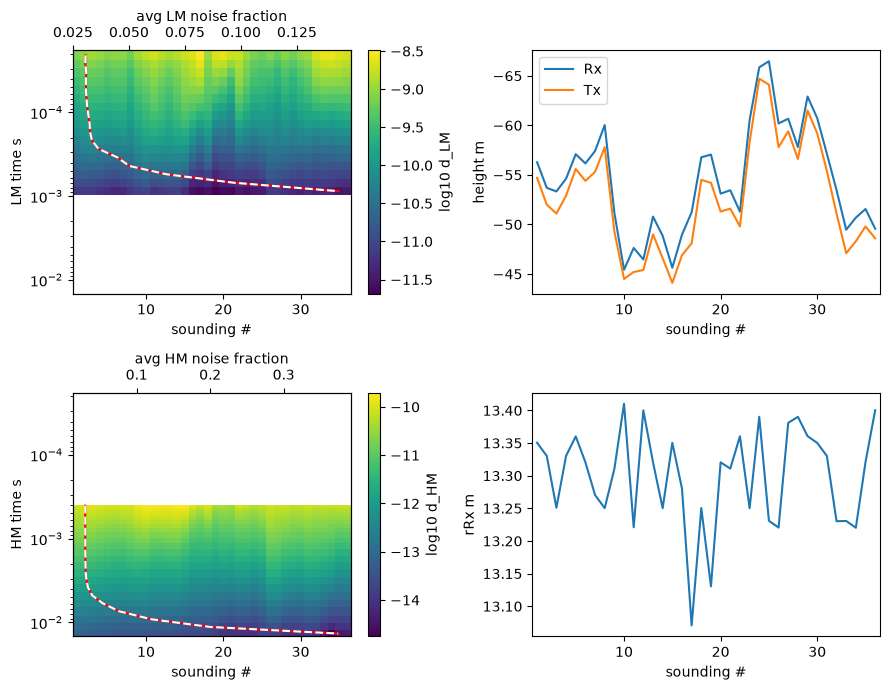

In [9]:
# datafile
fname_dat = "../00_required/SkyTEM_Menindee.dat"
zipsaveprefix = basename(fname_dat)
# electronics file with waveform, window times and filters
fname_specs_halt = "../00_required/skytem_electronics_halt.jl"
# column numbers from hdr file
X, Y, Z = 12, 13, 15
fid = 1
linenum = 2
frame_height = 9
frame_dx = 21
frame_dy = 22
frame_dz = 23
LM_Z = [26,42] # low moment columns
HM_Z = [43,67] # high moment columns
units = 1e-12  # V/(Am^2)
# read the electronics stuff from file
include(fname_specs_halt);
# create soundings array WITH decimation
soundings = transD_GP.SkyTEM1DInversion.read_survey_files(;fname_dat,
									 lowpassfcs, LM_times, HM_times, LM_ramp, HM_ramp,
									 LM_noise, HM_noise, rTx,
						             LM_Z, HM_Z, frame_height, frame_dz,
									 frame_dy, frame_dx, X, Y, Z, fid,
									 linenum,
                                     startfrom        = 1,
									 skipevery        = 20, ## **decimate!**
									 dotillsounding   = nothing,
									 units,
									 makeqcplots      = true);
@info "\nthere are $(length(soundings)) soundings"

# Discretisation and parameterisation options, same as synthetics

In [10]:
zfixed             = [-1e5]
ρfixed             = [1e12] # linear air resistivity Ωm
zstart             = 0.0
extendfrac         = 1.06   # percent extension
dz                 = 1.25   # thickness of first layer
nlayers            = 52     # number of layers in depth
ρbg                = 10     # linear air resistivity Ωm to check, not used in inversion
# make gradientinv options same for all soundings
# Occam stuff
σstart, σ0         = -2, -2 # log10 S/m
knownvalue         = 0.7
calcjacobian       = true
nstepsmax          = 40
lo                 = -2.5    # log10 S/m min conductivity
hi                 = 0.5     # log10 S/m max conductivity
λ²min              = 1       # 10^Tikhonov line search min
λ²max              = 3       # 10^Tikhonov line search max
ntries             = 10      # steps in the line search
β²                 = 0.5e-4  # strength of prior model
# L1 specific stuff
cd_maxiter         = 200_000 # coordinate descent inner steps
cd_tol             = 1e-6    # cd absolute tolerance
# QC
showgeomplot       = true   # toggle to true see discretisation
plotfield          = true   # toggle to see forward model for ρbg

true

# Plot random sounding with aem operator

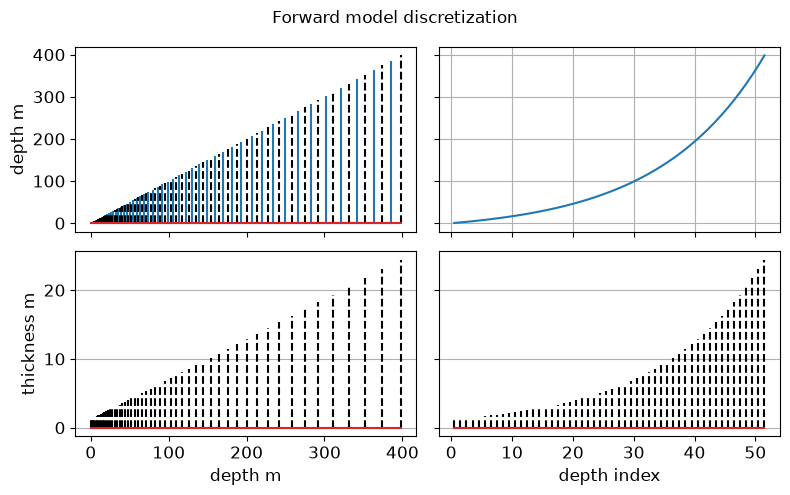

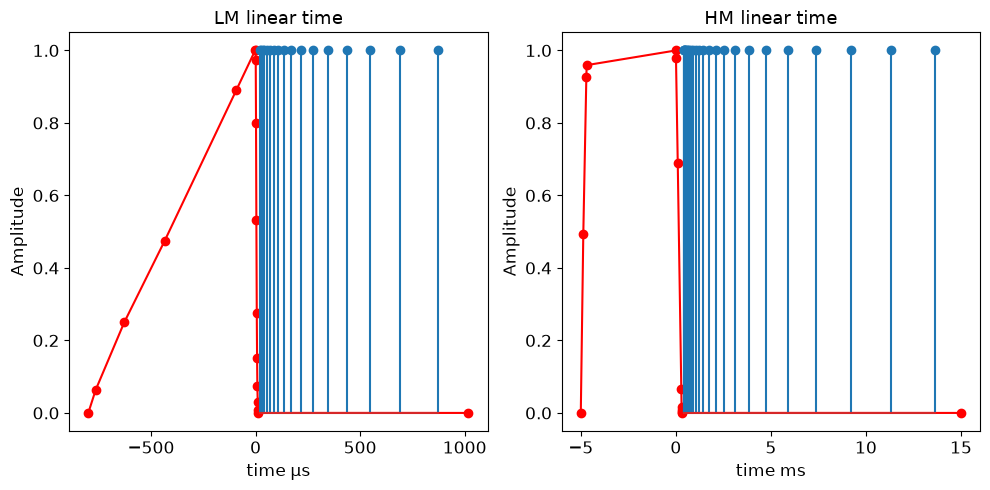

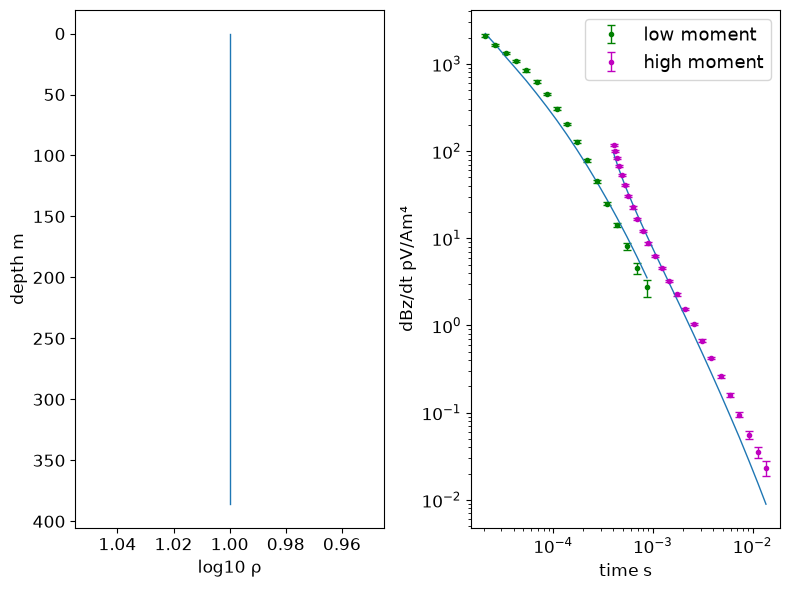

In [11]:
using Random
Random.seed!(111)
idxwell = rand(1:length(soundings)) # transD_GP.CommonToAll.getclosestidx(620436.75, 6428003, soundings)
aem, zall, = transD_GP.makeoperator(
    soundings[idxwell];
    zfixed, ρfixed, zstart, extendfrac, calcjacobian,
    dz, ρbg, nlayers, plotfield, showgeomplot);
# make the coordinate descent path explicit through L1transform
L1transform = transD_GP.R1Transform(aem);

# Sanity check inversion on random sounding

[ Info: iteration: 1 χ²: 11510.851088087453 target: 42
[ Info: iteration: 2 χ²: 2124.5687019753614 target: 42
[ Info: iteration: 3 χ²: 958.0628077576665 target: 42
[ Info: iteration: 4 χ²: 566.0463422755071 target: 42
[ Info: iteration: 5 χ²: 227.7561342170972 target: 42
[ Info: iteration: 6 χ²: 122.03227200125613 target: 42
[ Info: iteration: 7 χ²: 71.50187524096415 target: 42
[ Info: iteration: 8 χ²: 49.66615746525622 target: 42
[ Info: iteration: 9 χ²: 42.62167821106115 target: 42


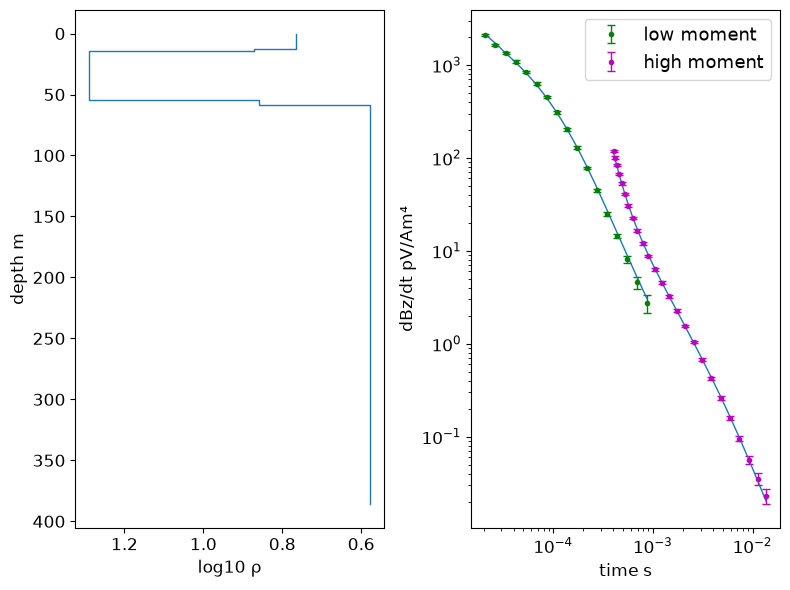

false

In [12]:
# convert value to arrays with map for test inversion
con_start, con_ref = map(x->x*ones(length(aem.ρ)-aem.nfixed), [σstart, σ0])
# run test inversion
m, χ², λ², idx = transD_GP.gradientinv(con_start, con_ref, aem;
                            nstepsmax, λ²min, λ²max, β², ntries,
                            knownvalue, lo, hi,
                            L1transform, cd_maxiter, cd_tol,
                            );
mlast = -m[end][idx[end]] ## get last model and convert to log10 resistivity
transD_GP.plotmodelfield!(aem, mlast) ## plot result
# make sure Jacobian calculation is switched on after test inversion
aem.Flow.calcjacobian, aem.Fhigh.calcjacobian = true, true
# delete previous run if it exists
isfile(zipsaveprefix*"_zipped.dat") && rm(zipsaveprefix*"_zipped.dat")

# Parallel inversion of soundings

In [13]:
# split into sequential iterations of parallel soundings
using Distributed
nsoundings = length(soundings)
nprocs() > 1 && rmprocs(workers()) ## if any workers existed from earlier runs
addprocs(6) ## Make sure you have at least 7 CPUs!
ncores = nworkers()
@info "there are $ncores workers"
nsequentialiters = ceil(Int, nsoundings/ncores)
@info "will require $(nsequentialiters) iterations with $(ncores) soundings per pass"
# set up HiQGA on all workers
@everywhere using Distributed
@everywhere using HiQGA.transD_GP
# do the parallel soundings
@info "starting"
transD_GP.loopacrossAEMsoundings(soundings, aem, σstart, σ0;
                            nsequentialiters, nstepsmax, ntries,
                            lo, hi, λ²min, λ²max, β², knownvalue,
                            zipsaveprefix,
                            verbose = true, ## lots of output if true!
                            # L1 stuff,
                            cd_maxiter, cd_tol, L1transform)

rmprocs(workers())

[ Info: there are 6 workers
[ Info: will require 6 iterations with 6 soundings per pass
[ Info: starting


      From worker 2:	[ Info: sounding_200613_692985.3_gradientinv.dat : iteration: 1 χ²: 18936.938692447573 target: 42
      From worker 5:	[ Info: sounding_200613_693015.3_gradientinv.dat : iteration: 1 χ²: 14489.349746239119 target: 42
      From worker 6:	[ Info: sounding_200613_693025.3_gradientinv.dat : iteration: 1 χ²: 15110.52180440231 target: 42
      From worker 3:	[ Info: sounding_200613_692995.3_gradientinv.dat : iteration: 1 χ²: 17639.317311449304 target: 42
      From worker 4:	[ Info: sounding_200613_693005.3_gradientinv.dat : iteration: 1 χ²: 15301.079128150712 target: 42
      From worker 7:	[ Info: sounding_200613_693035.3_gradientinv.dat : iteration: 1 χ²: 13028.458922716412 target: 42
      From worker 2:	[ Info: sounding_200613_692985.3_gradientinv.dat : iteration: 2 χ²: 16973.34067605415 target: 42
      From worker 6:	[ Info: sounding_200613_693025.3_gradientinv.dat : iteration: 2 χ²: 9190.747969447923 target: 42
      From worker 5:	[ Info: sounding_200613_693015

Task (done) @0x0000000301fdc970

# Plot results

idspec = idx[doesmatch] = 16


[ Info: 200613
[ Info: X, Y = 621979.3, 6.4265065e6
[ Info: ϕd is 1.015


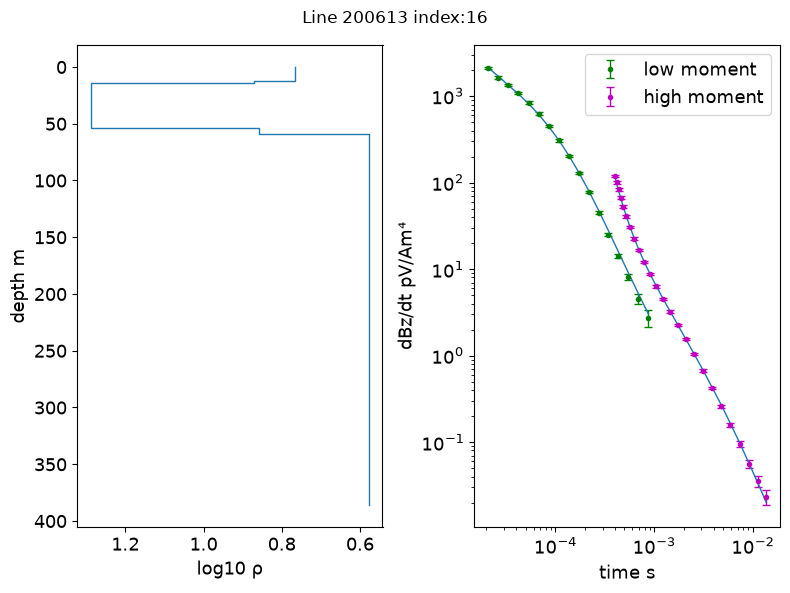

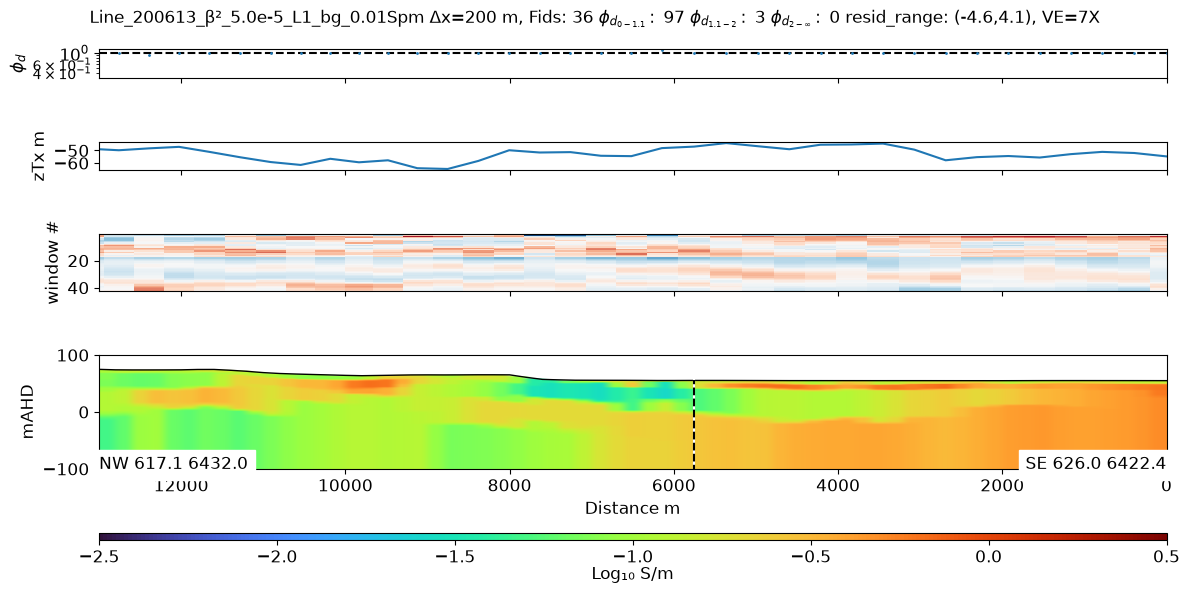

In [15]:
dr = 200 ## line interpolation distance in m
# plot result at particular idx and show results for whole line
yl=[-100,100] ## elevation plotting limits
transD_GP.plotconvandlast(soundings, dr, dz; zall, nnu=0,
    figsize=(12,6), vmin=lo, vmax=hi, postfix="β²_$(β²)_L1_bg_$(round(10. ^σ0, sigdigits=4))Spm", prefix=zipsaveprefix,
    preferEright=true, showplot=true, logscale=true, yl,calcresiduals=true,
    plotforward=true, aem_in=aem, idx=[idxwell], lnames=[200613]);

---

*This notebook was generated using [Literate.jl](https://github.com/fredrikekre/Literate.jl).*